In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import warnings
warnings.filterwarnings('ignore')

In [2]:
df = pd.read_csv("ai4i2020.csv")

In [3]:
df.head()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [4]:
df.tail()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
9995,9996,M24855,M,298.8,308.4,1604,29.5,14,0,0,0,0,0,0
9996,9997,H39410,H,298.9,308.4,1632,31.8,17,0,0,0,0,0,0
9997,9998,M24857,M,299.0,308.6,1645,33.4,22,0,0,0,0,0,0
9998,9999,H39412,H,299.0,308.7,1408,48.5,25,0,0,0,0,0,0
9999,10000,M24859,M,299.0,308.7,1500,40.2,30,0,0,0,0,0,0


In [5]:
df.shape

(10000, 14)

In [6]:
df.columns

Index(['UDI', 'Product ID', 'Type', 'Air temperature [K]',
       'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]',
       'Tool wear [min]', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF',
       'RNF'],
      dtype='object')

In [7]:
df.dtypes

,0
UDI,int64
Product ID,object
Type,object
Air temperature [K],float64
Process temperature [K],float64
Rotational speed [rpm],int64
Torque [Nm],float64
Tool wear [min],int64
Machine failure,int64
TWF,int64


In [8]:
df.columns = df.columns.str.strip()

print("Dataset loaded successfully")
print("Dataset shape:", df.shape)
print("\nFirst five rows:")
print(df.head())

print("\nColumn names:")
print(df.columns.tolist())

Dataset loaded successfully
Dataset shape: (10000, 14)

First five rows:
   UDI Product ID Type  Air temperature [K]  Process temperature [K]  \
0    1     M14860    M                298.1                    308.6   
1    2     L47181    L                298.2                    308.7   
2    3     L47182    L                298.1                    308.5   
3    4     L47183    L                298.2                    308.6   
4    5     L47184    L                298.2                    308.7   

   Rotational speed [rpm]  Torque [Nm]  Tool wear [min]  Machine failure  TWF  \
0                    1551         42.8                0                0    0   
1                    1408         46.3                3                0    0   
2                    1498         49.4                5                0    0   
3                    1433         39.5                7                0    0   
4                    1408         40.0                9                0    0   

   HDF 

In [9]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  object 
 2   Type                     10000 non-null  object 
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3), int64(9)

In [10]:
print("\nStatistical Summary:")
print(df.describe())


Statistical Summary:
               UDI  Air temperature [K]  Process temperature [K]  \
count  10000.00000         10000.000000             10000.000000   
mean    5000.50000           300.004930               310.005560   
std     2886.89568             2.000259                 1.483734   
min        1.00000           295.300000               305.700000   
25%     2500.75000           298.300000               308.800000   
50%     5000.50000           300.100000               310.100000   
75%     7500.25000           301.500000               311.100000   
max    10000.00000           304.500000               313.800000   

       Rotational speed [rpm]   Torque [Nm]  Tool wear [min]  Machine failure  \
count            10000.000000  10000.000000     10000.000000     10000.000000   
mean              1538.776100     39.986910       107.951000         0.033900   
std                179.284096      9.968934        63.654147         0.180981   
min               1168.000000      3.8000

In [11]:
print("\nMissing Values:")
print(df.isnull().sum())


Missing Values:
UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64


In [12]:
print("\nDuplicate Rows:", df.duplicated().sum())


Duplicate Rows: 0


In [13]:
print("\nMachine Failure Distribution:")
print(df["Machine failure"].value_counts())


Machine Failure Distribution:
Machine failure
0    9661
1     339
Name: count, dtype: int64


In [14]:
X = df.drop('Machine failure', axis=1)

In [15]:
y = df["Machine failure"]

In [16]:
print("Input shape:", X.shape)
print("Output shape:", y.shape)

Input shape: (10000, 13)
Output shape: (10000,)


In [17]:
categorical_features = ["Type"]

numerical_features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

In [18]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)
print("Training sample:", X_train.shape[0])
print("Testing sample:", X_test.shape[0])

Training sample: 8000
Testing sample: 2000


In [19]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

numeric_features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]
categorical_features = ["Type"]

numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])
print("Preprocessor created successfully!")

Preprocessor created successfully!


In [20]:
linear_svm = Pipeline([
    ("preprocessor", preprocessor),
    ("svm", SVC(kernel="linear", C=1.0))
])

linear_svm.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Air temperature [K]',
                                                   'Process temperature [K]',
                                                   'Rotational speed [rpm]',
                                                   'Torque [Nm]',
                                                   'Tool wear [min]']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['Type'])])),
                ('svm', SVC(kernel='linear'))])

In [21]:
y_pred_linear = linear_svm.predict(X_test)

In [22]:
accuracy_linear = accuracy_score(y_test, y_pred_linear)
precision_linear = precision_score(y_test, y_pred_linear, zero_division=0)
recall_linear = recall_score(y_test, y_pred_linear, zero_division=0)
f1_linear = f1_score(y_test, y_pred_linear, zero_division=0)
print("Linear SVM Results:")
print("Accuracy:", accuracy_linear)
print("Precision:", precision_linear)
print("Recall:", recall_linear)
print("F1-score:", f1_linear)

Linear SVM Results:
Accuracy: 0.966
Precision: 0.0
Recall: 0.0
F1-score: 0.0


In [23]:
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV

svm_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", SVC())
])

In [24]:
param_grid = [
    {
        "classifier__kernel": ["linear"],
        "classifier__C": [0.1, 1, 10, 100]
    },
    {
        "classifier__kernel": ["rbf"],
        "classifier__C": [0.1, 1, 10, 100],
        "classifier__gamma": ["scale", 0.01, 0.1, 1]
    }
]

grid_search = GridSearchCV(
    estimator=svm_pipeline,
    param_grid=param_grid,
    scoring="f1",
    cv=3,
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

print("Best Parameters:", grid_search.best_params_)
print("Best CV F1-score:", grid_search.best_score_)

Fitting 3 folds for each of 20 candidates, totalling 60 fits
Best Parameters: {'classifier__C': 100, 'classifier__gamma': 'scale', 'classifier__kernel': 'rbf'}
Best CV F1-score: 0.6878949923116368


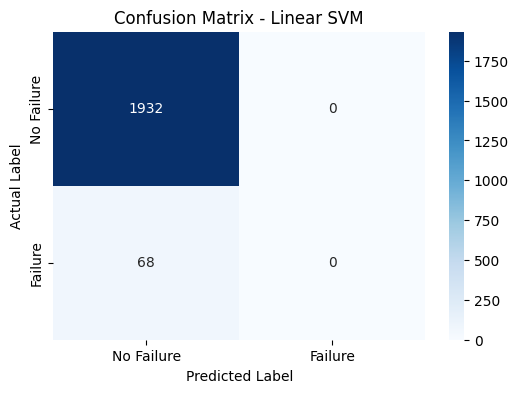

In [25]:
cm_linear = confusion_matrix(y_test, y_pred_linear)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm_linear,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Failure", "Failure"],
    yticklabels=["No Failure", "Failure"]
)

plt.title("Confusion Matrix - Linear SVM")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()

In [26]:
# Reconstructed from the PDF line that was cut off after "gamm..."
rbf_svm = Pipeline([
    ("preprocessor", preprocessor),
    ("svm", SVC(kernel="rbf", C=1.0, gamma="scale"))
])
rbf_svm.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Air temperature [K]',
                                                   'Process temperature [K]',
                                                   'Rotational speed [rpm]',
                                                   'Torque [Nm]',
                                                   'Tool wear [min]']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['Type'])])),
                ('svm', SVC())])

In [27]:
y_pred_rbf = rbf_svm.predict(X_test)

In [28]:
accuracy_rbf = accuracy_score(y_test, y_pred_rbf)
precision_rbf = precision_score(y_test, y_pred_rbf, zero_division=0)
recall_rbf = recall_score(y_test, y_pred_rbf, zero_division=0)
f1_rbf = f1_score(y_test, y_pred_rbf, zero_division=0)
print("Linear SVM Results:")
print("Accuracy:", accuracy_rbf)
print("Precision:", precision_rbf)
print("Recall:", recall_rbf)
print("F1-score:", f1_rbf)

Linear SVM Results:
Accuracy: 0.972
Precision: 0.875
Recall: 0.20588235294117646
F1-score: 0.3333333333333333


In [29]:
from sklearn.metrics import classification_report

# Generate predictions using the best GridSearchCV model
pred = grid_search.best_estimator_.predict(X_test)

# Print classification report
print("\nClassification Report:")
print(classification_report(
    y_test,
    pred,
    labels=[0, 1],
    target_names=["No Failure", "Failure"],
    zero_division=0
))


Classification Report:
              precision    recall  f1-score   support

  No Failure       0.99      0.99      0.99      1932
     Failure       0.76      0.60      0.67        68

    accuracy                           0.98      2000
   macro avg       0.87      0.80      0.83      2000
weighted avg       0.98      0.98      0.98      2000



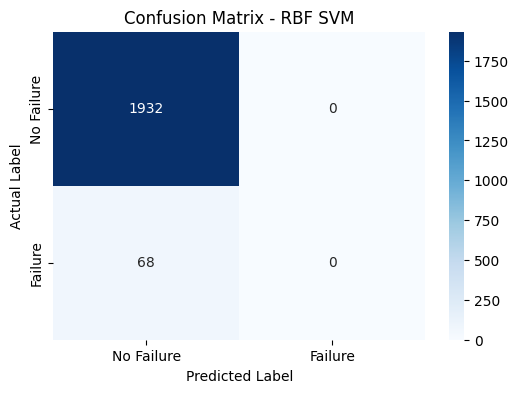

In [30]:
cm_rbf = confusion_matrix(y_test, y_pred_rbf)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm_linear,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Failure", "Failure"],
    yticklabels=["No Failure", "Failure"]
)

plt.title("Confusion Matrix - RBF SVM")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()

In [31]:
comparison_plot = pd.DataFrame({
    "Kernel": ["Linear", "RBF"],
    "Accuracy": [accuracy_linear, accuracy_rbf],
    "Precision": [precision_linear, precision_rbf],
    "Recall": [recall_linear, recall_rbf],
    "F1-score": [f1_linear, f1_rbf]
})

print(comparison_plot.round(4))

   Kernel  Accuracy  Precision  Recall  F1-score
0  Linear     0.966      0.000  0.0000    0.0000
1     RBF     0.972      0.875  0.2059    0.3333


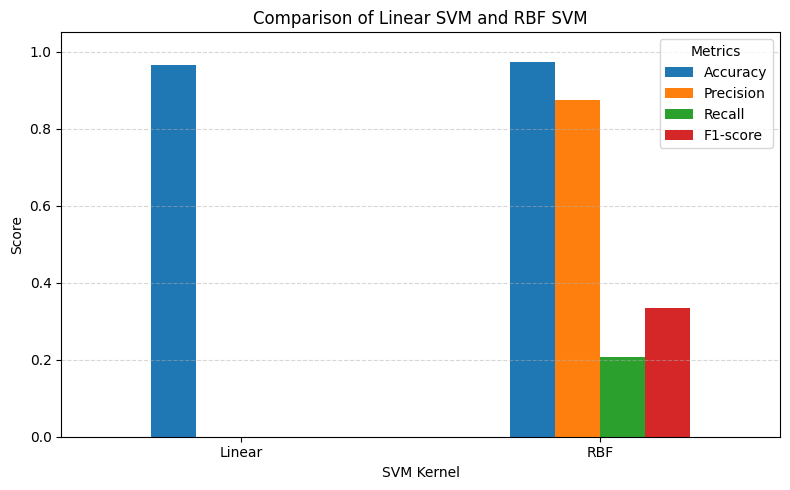

In [32]:
comparison_plot.set_index("Kernel").plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Comparison of Linear SVM and RBF SVM")
plt.xlabel("SVM Kernel")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.legend(title="Metrics")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

In [33]:
from sklearn.pipeline import Pipeline

pipeline = Pipeline(
    steps=[("preprocessor", preprocessor), ("classifier", SVC())]
)

In [34]:
param_grid = [
    {
        "classifier__kernel": ["linear"],
        "classifier__C": [0.1, 1, 10, 100]
    },
    {
        "classifier__kernel": ["rbf"],
        "classifier__C": [0.1, 1, 10, 100],
        "classifier__gamma": ["scale", 0.01, 0.1, 1]
    }
]

In [35]:
# Reconstructed from the PDF line that was cut off after "n_"
grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    cv=5,
    scoring="f1",
    n_jobs=-1,
    verbose=1
)

In [36]:
grid_search.fit(X_train, y_train)

print("Best Parameters:", grid_search.best_params_)
print("Best Cross-Validation F1-score:", grid_search.best_score_)

Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best Parameters: {'classifier__C': 100, 'classifier__gamma': 'scale', 'classifier__kernel': 'rbf'}
Best Cross-Validation F1-score: 0.7080372186703207


In [37]:
best_model = grid_search.best_estimator_
y_pred_grid = best_model.predict(X_test)

print("\nGrid Search Test Results:")
print("Accuracy:", accuracy_score(y_test, y_pred_grid))
print("Precision:", precision_score(y_test, y_pred_grid, zero_division=0))
print("Recall:", recall_score(y_test, y_pred_grid, zero_division=0))
print("F1-score:", f1_score(y_test, y_pred_grid, zero_division=0))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_grid, zero_division=0))


Grid Search Test Results:
Accuracy: 0.98
Precision: 0.7592592592592593
Recall: 0.6029411764705882
F1-score: 0.6721311475409836

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      1932
           1       0.76      0.60      0.67        68

    accuracy                           0.98      2000
   macro avg       0.87      0.80      0.83      2000
weighted avg       0.98      0.98      0.98      2000



In [38]:
final_comparison = pd.DataFrame({
    "Model": ["Linear SVM", "RBF SVM", "Tuned SVM"],
    "Accuracy": [
        accuracy_linear,
        accuracy_rbf,
        accuracy_score(y_test, y_pred_grid)
    ],
    "Precision": [
        precision_linear,
        precision_rbf,
        precision_score(y_test, y_pred_grid, zero_division=0)
    ],
    "Recall": [
        recall_linear,
        recall_rbf,
        recall_score(y_test, y_pred_grid, zero_division=0)
    ],
    "F1-score": [
        f1_linear,
        f1_rbf,
        f1_score(y_test, y_pred_grid, zero_division=0)
    ]
})

final_comparison

,Model,Accuracy,Precision,Recall,F1-score
0,Linear SVM,0.966,0.000000,0.000000,0.000000
1,RBF SVM,0.972,0.875000,0.205882,0.333333
2,Tuned SVM,0.980,0.759259,0.602941,0.672131
